# Demo: GA vs BPSO vs Random Search

Menjalankan konfigurasi terbaik ketiga algoritma pada satu instance, iterasi per iterasi, dengan seed dan budget yang sama seperti notebook percobaan. Yang ditampilkan:

- kurva konvergensi (gap ke optimum brute-force) yang bergerak
- alokasi dieset ke mesin dari solusi terbaik tiap algoritma, dibanding optimum
- beban tiap mesin terhadap kapasitas
- tabel cost, gap, evaluasi, dan waktu

In [1]:
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.animation import PillowWriter

from src.evaluation.demo import Demo
from src.paths import FIGURES_DIR

## Parameter

In [2]:
INSTANCE = 19     # 3 | 9 | 13 | 16 | 18 | 19
SEED = None       # None = seed pertama dari master seed di configs/experiment.json
BUDGET = None     # None = max_evaluations dari configs/experiment.json
STEP = 50         # evaluasi per frame animasi
DELAY = 0.05      # jeda antar frame (detik)

## Jalankan Demo

instance 19 dieset, seed 1829338324, optimum brute-force 6,112,960.59


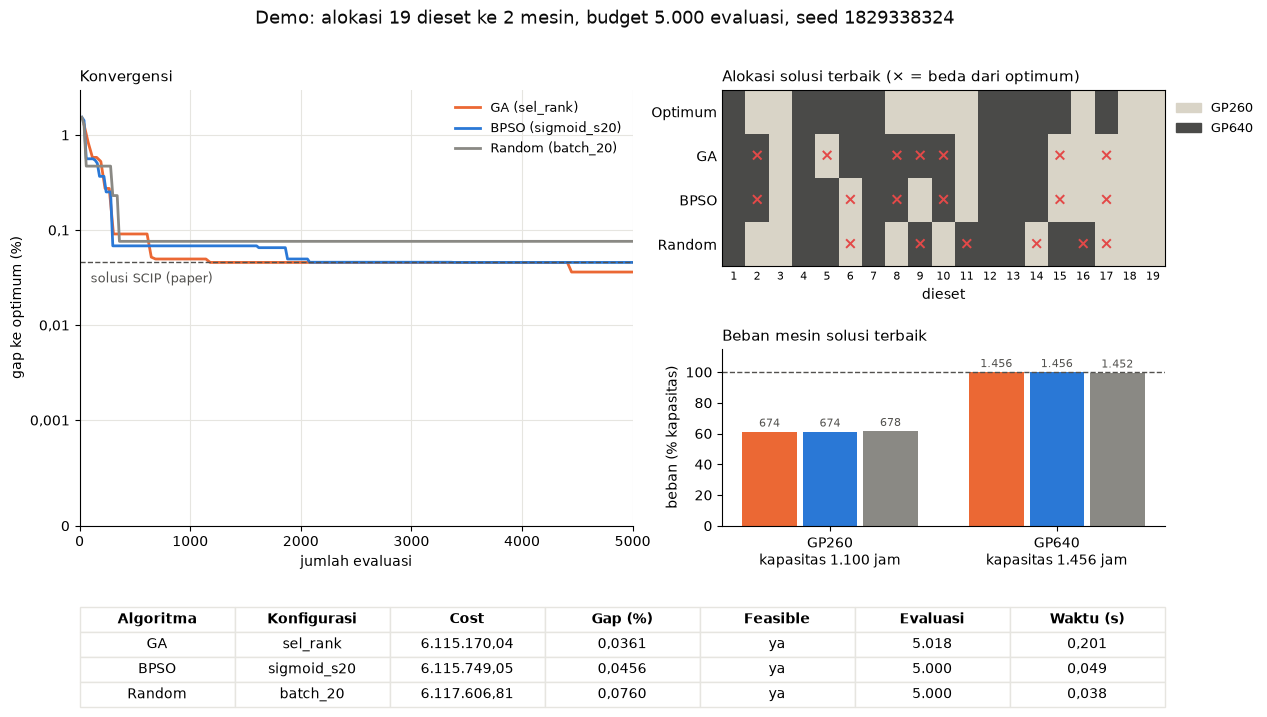

In [3]:
demo = Demo(INSTANCE, seed=SEED, budget=BUDGET, step=STEP)
print(f"instance {INSTANCE} dieset, seed {demo.seed}, optimum brute-force {demo.opt_cost:,.2f}")

handle = display(demo.fig, display_id=True)
plt.close(demo.fig)   # cegah gambar tampil dua kali
for _ in demo.frames():
    handle.update(demo.fig)
    time.sleep(DELAY)

## Hasil Akhir

Tabel diurutkan dari gap terkecil. Baris terakhir adalah solusi SCIP dari paper sebagai pembanding. Penjelasan di bawahnya dibuat dari hasil run ini, ditambah konteks 30 run dari `comparison.ipynb`.

In [4]:
from IPython.display import Markdown

display(demo.result_table())
display(Markdown(demo.explanation()))

,Algoritma,Konfigurasi,Cost,Selisih ke optimum,Gap (%),Dieset beda dari optimum,Feasible,Evaluasi sampai terbaik,Waktu (s)
Peringkat,,,,,,,,,
1,GA,sel_rank,"6.115.170,04","2.209,45","0,0361",7 dari 19,ya,4.448,"0,201"
2,BPSO,sigmoid_s20,"6.115.749,05","2.788,46","0,0456",6 dari 19,ya,3.380,"0,049"
3,Random,batch_20,"6.117.606,81","4.646,22","0,0760",6 dari 19,ya,360,"0,038"
-,Solusi SCIP (paper),-,"6.115.761,14","2.800,55","0,0458",-,ya,-,-


**Hasil run ini** (instance 19 dieset, seed 1829338324, 5.000 evaluasi per algoritma)

- Gap terkecil diperoleh **GA** (0,0361%), diikuti BPSO (0,0456%) dan random search (0,0760%).
- Solusi SCIP dari paper memiliki gap 0,0458% terhadap optimum brute-force; GA dan BPSO menghasilkan solusi lebih murah daripada solusi tersebut.
- Semua solusi akhir feasible. Mesin GP640 terisi 99,7–100,0% dari kapasitasnya: solusi murah memindahkan sebanyak mungkin dieset ke mesin yang lebih murah sampai kapasitasnya hampir penuh.

**Konteks dari 30 run percobaan** (`exp_results/tables/comparison/`)

- Gap rata-rata: GA 0,0338%, BPSO 0,0308%, random search 0,0948%.
- GA vs random search: berbeda signifikan (Wilcoxon, p < 0,001); GA lebih baik.
- GA vs BPSO: tidak berbeda signifikan (Wilcoxon, p = 0,663).
- random search vs BPSO: berbeda signifikan (Wilcoxon, p < 0,001); BPSO lebih baik.
- Hasil satu seed bisa berbeda dari kesimpulan di atas. Kesimpulan ditarik dari 30 run, bukan dari satu demo.

## Simpan Animasi (opsional)

Untuk bahan video demo cadangan.

In [5]:
out = FIGURES_DIR / "demo" / f"demo_{INSTANCE}_diesets.gif"
out.parent.mkdir(parents=True, exist_ok=True)

recording = Demo(INSTANCE, seed=SEED, budget=BUDGET, step=STEP)
writer = PillowWriter(fps=round(1 / DELAY))
with writer.saving(recording.fig, out, dpi=90):
    for _ in recording.frames():
        writer.grab_frame()
plt.close(recording.fig)
print("disimpan ke", out.relative_to(ROOT))

disimpan ke exp_results/figures/demo/demo_19_diesets.gif
